# Analysis 1 — Treasury Market Conditions and Scenarios

## Setup — Treasury data

In [1]:
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

from bondview.data.fred import FredDataManager
from bondview.analysis.treasury_curve import analyze_curve
from bondview.plotting.treasury_curve import show_yield_history
from bondview.presentation.treasury_curve import show_curve_results
from bondview.presentation.widgets import DateRangePicker

# Set the repository root explicitly if starting Jupyter outside the project.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data/fred/treasury_yields_261022_long.csv"

### Load Treasury yield observations

This is the only step that can contact FRED. Missing observations remain missing; the manager retains provenance independently of DataFrame attributes.

In [2]:
DATA_MODE = "file" # "download" or "file"
start = None
end = None
fred = FredDataManager(DATA_PATH, env_path=PROJECT_ROOT / ".env")
observations = fred.load_or_download(DATA_MODE, start=start, end=end)
fred.report()

FRED / Federal Reserve H.15 | Retrieved: 2026-10-26T11:02:46.425982+00:00
Loaded coverage: 1962-01-02 to 2026-10-22 | 16908 rows | /home/lbk/works/bondview-v3/data/fred/treasury_yields_261022_long.csv
DGS2: Percent, D; missing: 4313
DGS10: Percent, D; missing: 721
DGS30: Percent, D; missing: 4491
Retrieval-time snapshot; historical data availability at the observation date is not reconstructed.


In [3]:
# Initialize the date range picker
date_range = DateRangePicker(observations)

## A. Yield-curve conditions and movements

Examine 2Y, 10Y, and 30Y Treasury yields and compare available observations within the selected date range.

### Treasury yield history

Plot historical 2Y, 10Y, and 30Y Treasury yields over the selected date range.

In [4]:
date_range

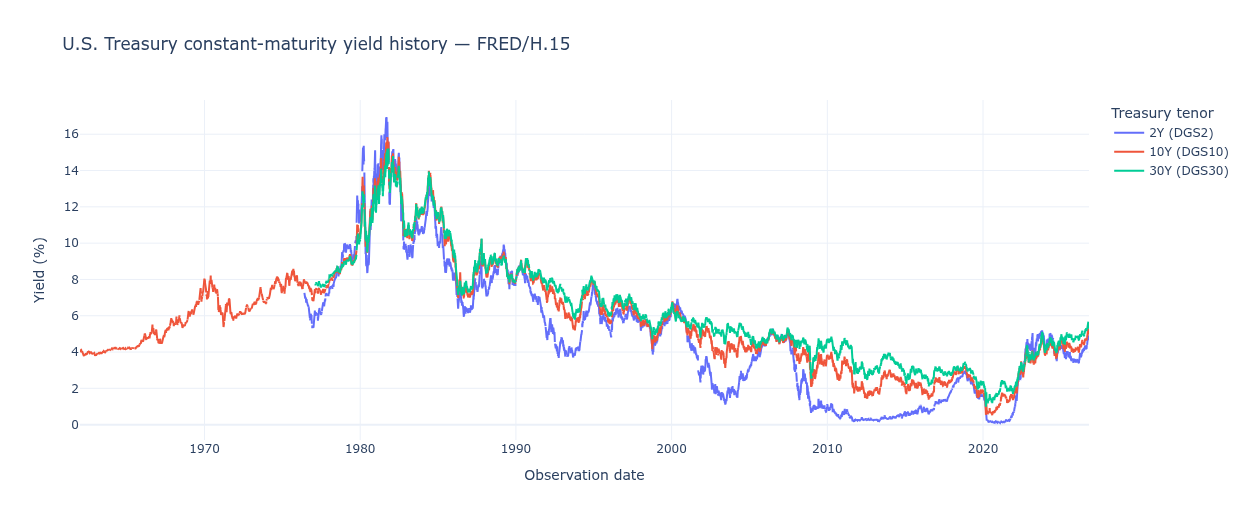

In [5]:
history_figure = show_yield_history(
    observations, *date_range.get_dates()
)

### Treasury yield and curve movements

Calculate yield and spread changes between selected dates, classify curve movements, and display the results

In [6]:
result = analyze_curve(
    observations, *date_range.get_dates(),
    yield_change_tolerance_bp=5,
    slope_tolerance_bp=5,
)
show_curve_results(result)

,1962-01-02,2026-10-22,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,N/A,4.65%,N/A,—,N/A
10Y yield,4.06%,4.96%,+90 bp,—,Yield rose
30Y yield,N/A,5.29%,N/A,—,N/A
10Y−2Y spread,N/A,+31 bp,N/A,N/A → Upward-sloping,N/A
30Y−10Y spread,N/A,+33 bp,N/A,N/A → Upward-sloping,N/A


Greatest upward yield movement among available tenors: 10Y (+90 bp). This comparison is partial because some endpoint observations are unavailable. 10Y−2Y spread: N/A. 30Y−10Y spread: N/A. These are net endpoint movements, not the full path or a forecast.

## B. Expected short rates and term premiums

### Load KW model estimates

### 2Y and 10Y yield decomposition

## C. Conditional joint yield movements

### Investor-conditioned historical scenarios

### KW expectations-conditioned historical scenarios

### Joint scenario-set summary